# Classification V/S Regression using Gradient Boosting

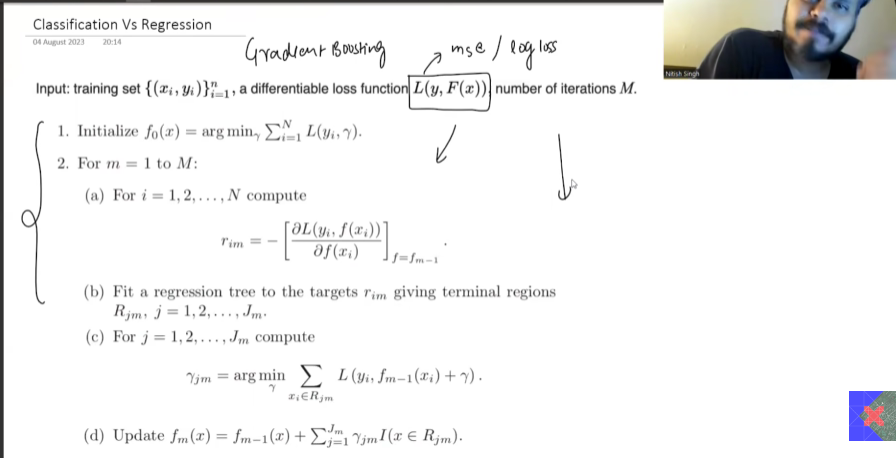

-  The exact same algorithm is used for both regression and classification, but the only difference is the loss function. For regression, we use the squared error loss function, and for classification, we use the log loss function.

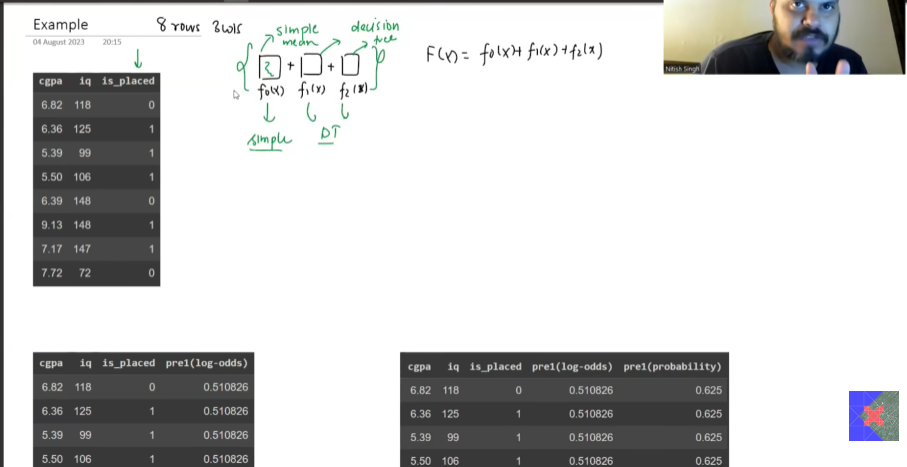

- So, our GB ensemble for classification will have 3 models, 1st one will be very simple 2nd and 3rd will be Desicion trees

# Stage 1: Find $f_0(x)$

- Here as we are doing classification, so we cant use mean of the target variable as the initial prediction, instead we will use the log odds of the target variable.

$$ log(odds) =  log (\frac{no. of successes}{no. of failures}) $$

- We are using log base $e$

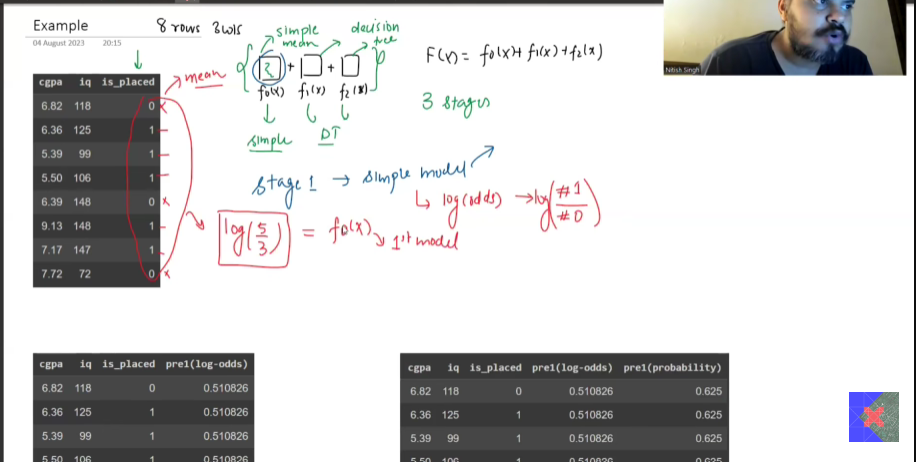

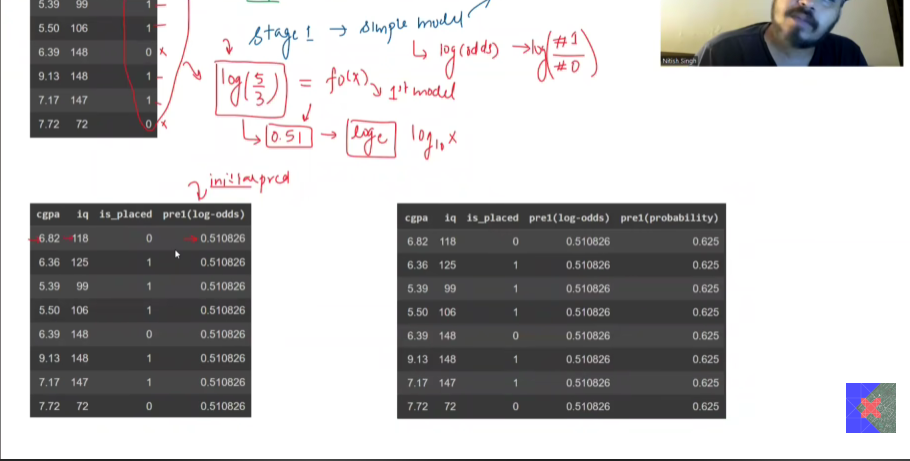

- But going forward, we will be calculating residuals, for that we will be needing the predicted probabilities instead of log odds (as is_placed is also giving probabilities ), so we will convert the log odds to predicted probabilities using the following formula:

$$ p = \frac{1}{1 + e^{-log(odds)}} $$

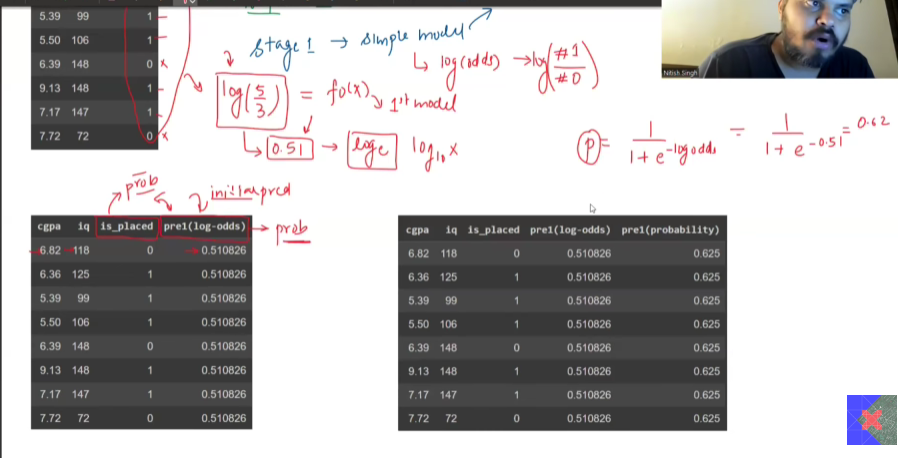

- SO humare first model ko koi vhi {cgpa,iq} input do, wo humesha 0.625 predict karega, since it is a classification problem let's use threshold of 0.5 to classify the predicted probabilities into classes.

- So > 0.5 = 1 (placed) and < 0.5 = 0 (not placed)

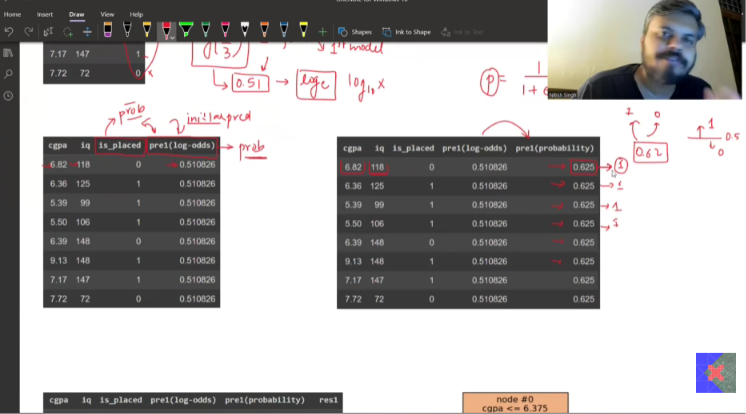

- So regression setting mei mean karta hai, whi classification setting mei log odds karta hai 

- So before going to stage 2, we need to calculate the pseudo residuals.

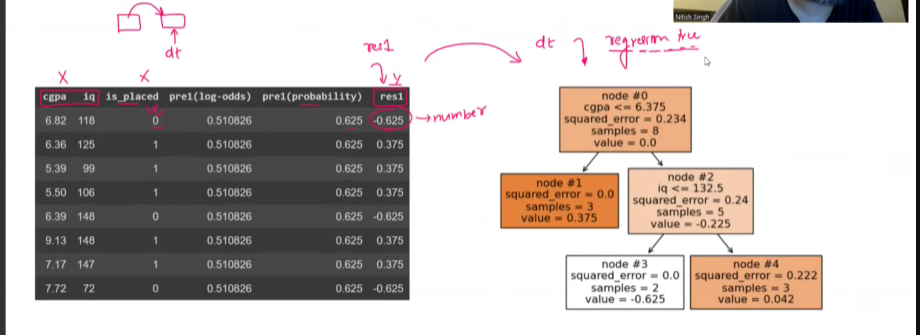

# Stage 2: Find $f_1(x)$

- Train the regression desicion tree (as residual are real values) on the pseudo residuals calculated in stage 1, and then find the terminal regions of the desicion tree.
- Now for calculating output after stage 2 generally we would use the mean of the residuals in each terminal region, but since we are doing classification, we will use the log odds so we need to convert the residuals into log odds using the following formula:

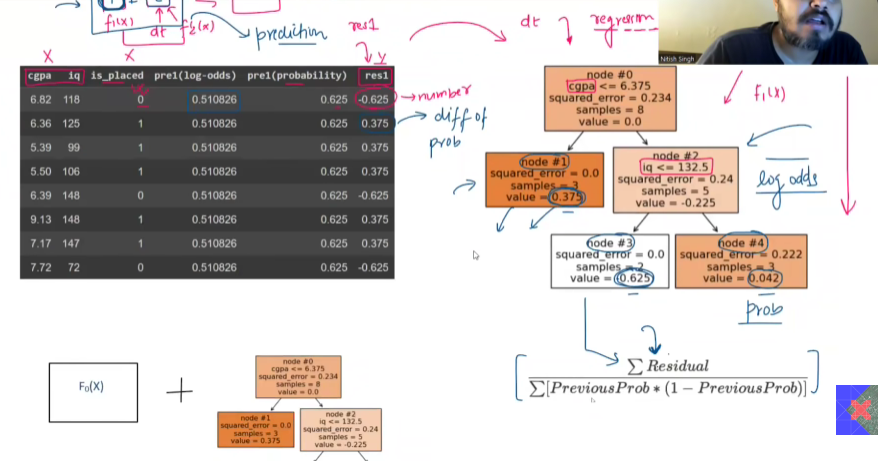

- Now, we will have to calculate the log odds for each terminal region

- So first we have to find the rows belonging to each terminal region (that you can find using a sklearn function)

- Then you can find the sum of residuals of the rows belonging to that terminal region (numerator of the formula)

- And previous_probability the predicted probability by the previous model for the rows belonging to that terminal region.

- So take sum of prevProbab(prevProbab - 1) for the rows belonging to that terminal region (denominator of the formula)

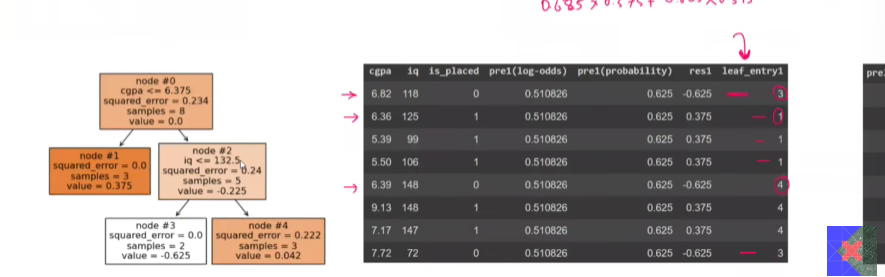


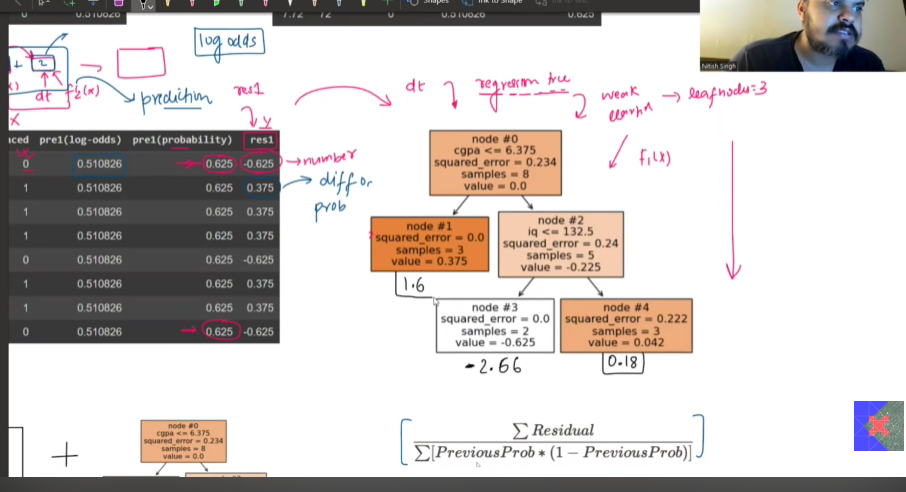

- So, now that we have the log odds for each terminal region, we can convert them into predicted probabilities using the following formula:

$$ PREDICTION  = f_0(x) + f_1(x) $$

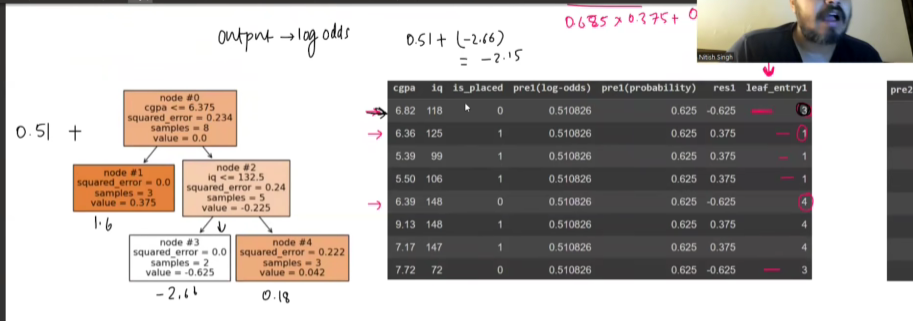

- Where value of $f_1(x)$ is the log odds for the terminal region where the given input falls, and $f_0(x)$ is the initial prediction we made in stage 1.

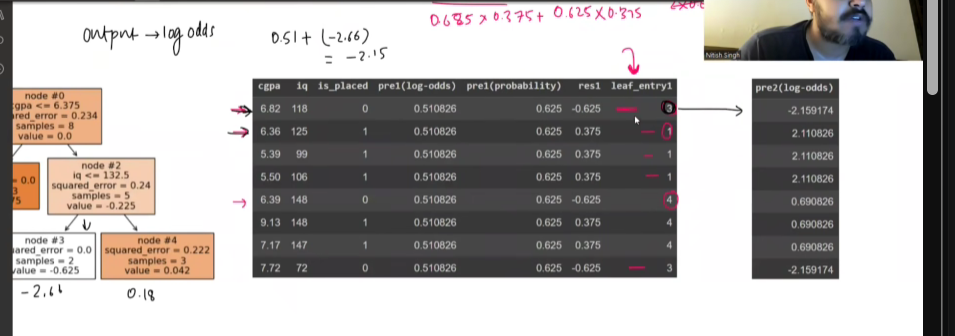

- But now again we have to convert the log odds into predicted probabilities  to calculate the pseudo residuals for stage 3 to use it as target variable for training the desicion tree in stage 3.

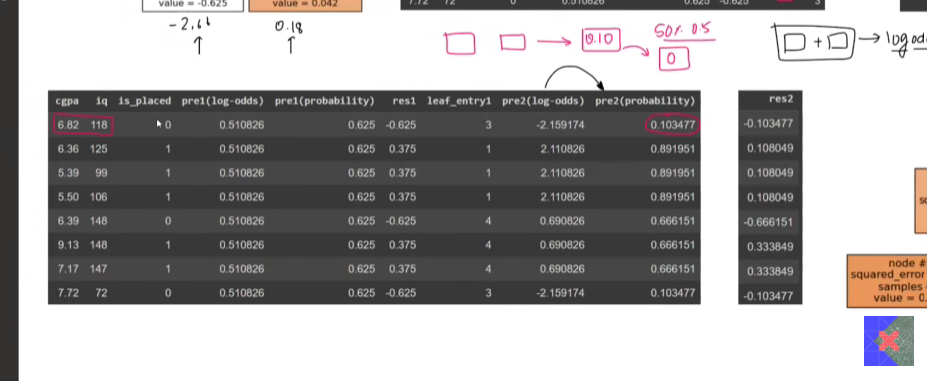

- If we had to predict based on the 2 models, then we would look at the probabilities (not log odds) and use the threshold of 0.5 to classify the predicted probabilities into classes.

# Stage 3: Find $f_2(x)$

- Now train the regression desicion tree (as residual are real values) on the pseudo residuals calculated in stage 2, and then find the terminal regions of the desicion tree.

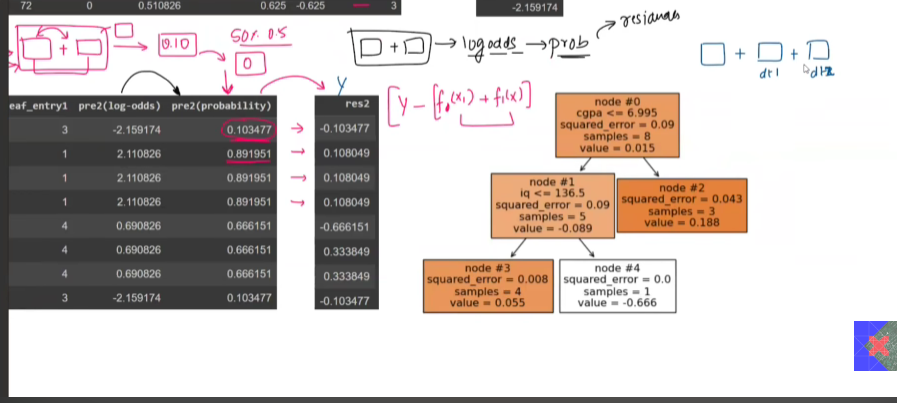

- convert the predicted residuals (residuals were difference of actual and predicted probabilities) into log odds

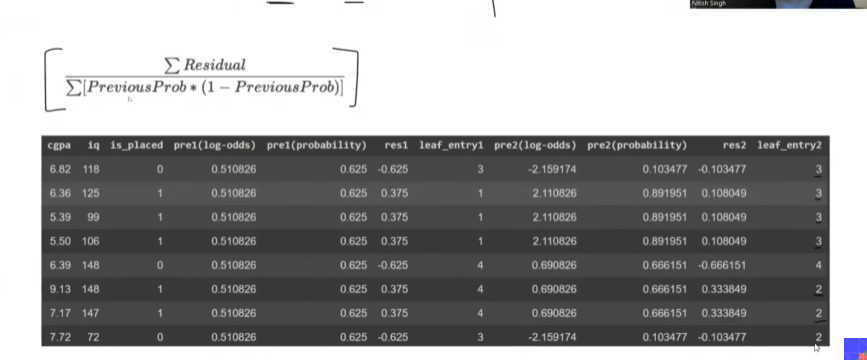

- We can find using a sklearn function, that which rows belong to which terminal region, and then we can assign the log odds for each terminal region to the rows belonging to that terminal region.

- Then use the log odds to calculate the final predicted probabilities using the following formula:

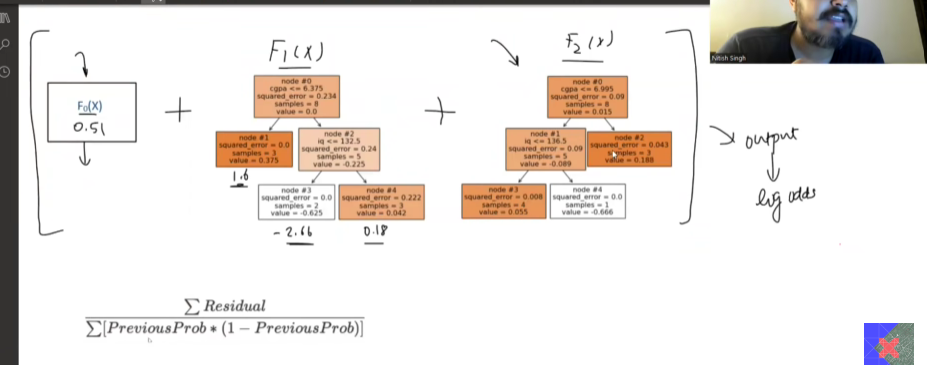

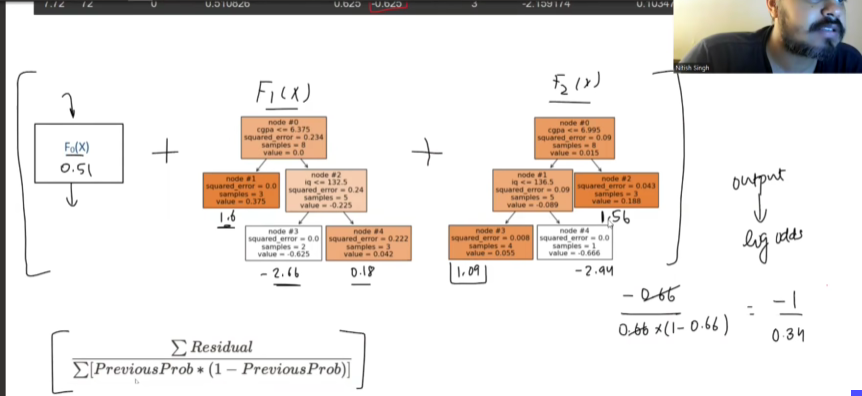

$$ PREDICTION  = f_0(x) + f_1(x) + f_2(x) $$

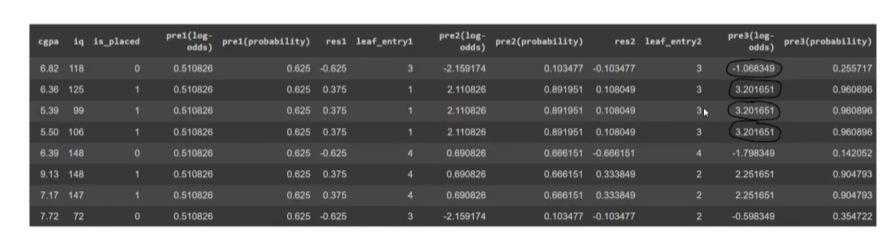

- Now convert the log of odds of the combined 3 models to probability, and then based on threshold of 0.5 classify the predicted probabilities into classes.

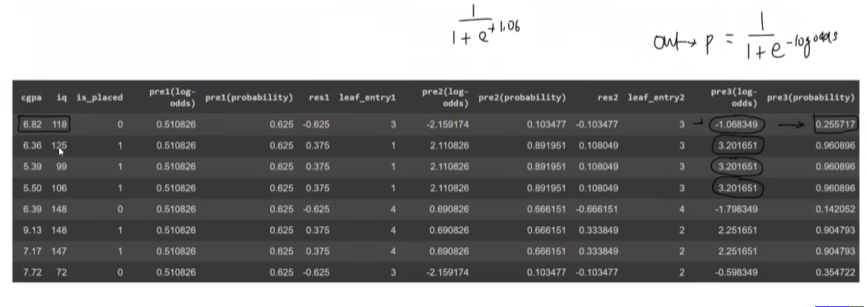

- As you add models you can see the residuals are getting smaller and smaller, but to avoid long jumps use learning rate 

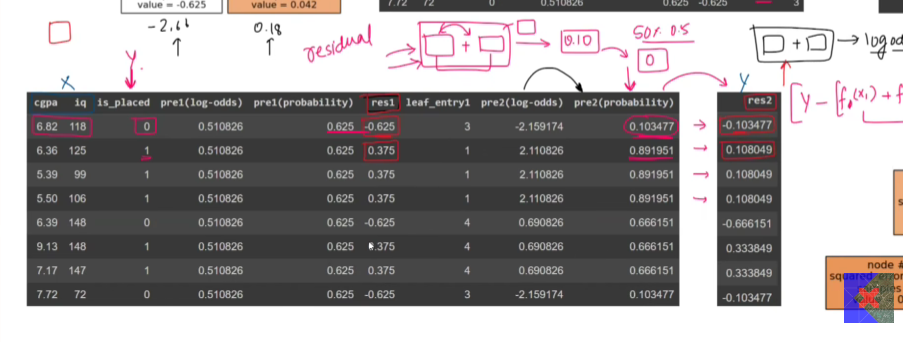

# Prediction for a new input

- cgpa = 7.2, iq = 100 , predict the probability of getting placed and the class.

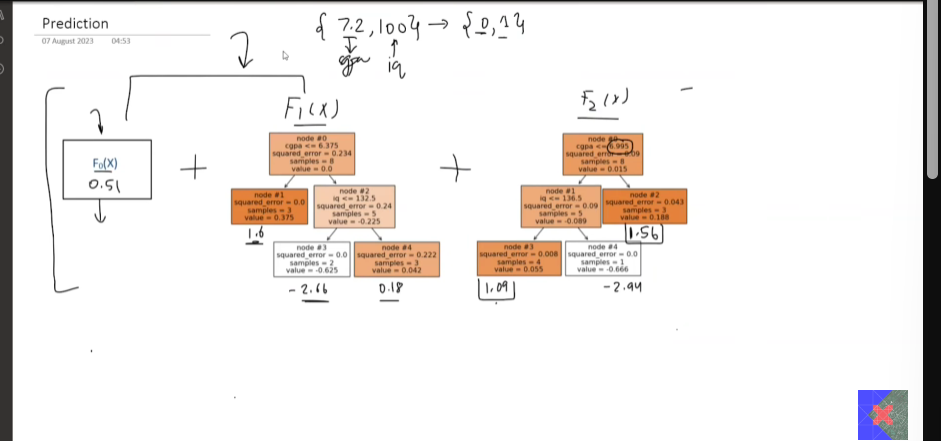

- The black values written near the leaf nodes are the log odds for that terminal region, and the `values` written inside the leaf nodes are the predicted residuals (probabilities difference) for that terminal region.

- so for the new input first we will calcuate the log of odd values from the 3 models and then add them to get the final log of odds, and then convert it into predicted probability and then classify it into class based on threshold of 0.5.

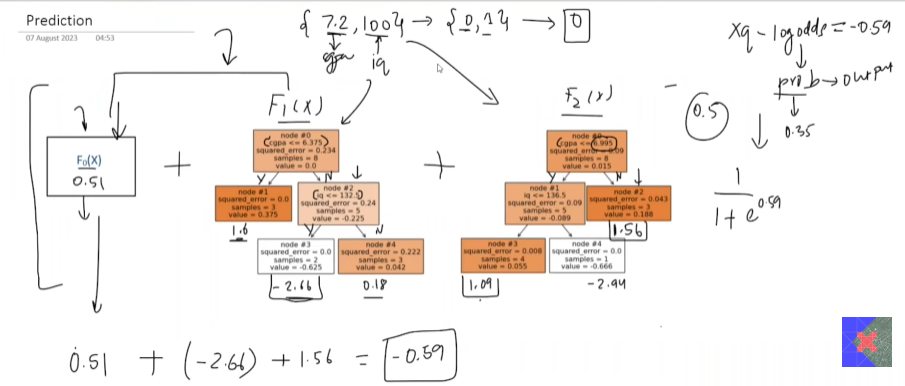

# Geometric Intuition of Gradient Boosting for Classification

See the geometric intuiton section of the video: (link)[https://www.youtube.com/watch?v=4p5EQtyxSyI&list=PLKnIA16_Rmvbr7zKYQuBfsVkjoLcJgxHH&index=122]